# Chapitre 4 - Exercices 4.7 à 4.10

Ce notebook traite les exercices 4.7 à 4.10, centrés sur les flux de données :

- **4.7** : modèle de Markov des champs perdus pendant un déploiement progressif
  (calcul et simulation) ;
- **4.8** : dimensionner le stockage et le transport du schéma de l'écrivain (calcul) ;
- **4.9** : quels changements d'API sont sûrs, selon l'ordre de déploiement ?
  (raisonnement et vérification) ;
- **4.10** : délais d'expiration, relances et doublons d'un appel distant (calcul et
  simulation).

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)
rng = np.random.default_rng(0)

## Exercice 4.7 : combien de champs perdus pendant un déploiement ?

**Énoncé.** On reprend la simulation du cours 2 (`E.simulate_rolling_upgrade`) : 2 000
enregistrements, 10 nœuds, 60 mises à jour par pas de temps, chacune sur un enregistrement
et par un nœud tirés au hasard. Le nœud $k$ ($k = 0..9$) passe en v2 au pas $20 + 10k$. Une
mise à jour par un nœud v2 permet d'ajouter une photo si l'enregistrement n'en a jamais
eu ; une mise à jour par un nœud v1 efface la photo (il ne préserve pas les champs
inconnus).

1. Modéliser **un** enregistrement par une chaîne de Markov à trois états (sans photo,
   avec photo, photo perdue) et calculer exactement la fraction d'enregistrements dont la
   photo est perdue à la fin. Comparer à la simulation.
2. Montrer que, pour une part de nœuds v2 qui croît linéairement de 0 à 1 sur une durée
   $D$, un enregistrement qui reçoit sa photo à l'instant $\tau$ la conserve avec
   probabilité $\exp(-\lambda (D-\tau)^2 / (2D))$, où $\lambda$ est le taux de mises à jour
   par enregistrement.
3. Comment la perte évolue-t-elle si le déploiement dure deux ou quatre fois plus
   longtemps ? Qu'en conclure ?

**Rappels.** Un ancien code qui décode dans son modèle d'objet et réécrit efface les
champs inconnus (cours 1, section 1 ; cours 2, section 4). Pendant le déploiement, la part
$s(t)$ de nœuds v2 croît.

**Solution.**

*1.* À chaque mise à jour, l'enregistrement est visé avec probabilité $q = 1/2000$ ; le
nœud est v2 avec probabilité $s(t)$. Transitions : sans photo -> avec photo avec
probabilité $q\,s(t)$ ; avec photo -> perdue avec probabilité $q\,(1 - s(t))$ ; « perdue »
est absorbant (l'utilisateur ne la remet pas). On propage le vecteur de probabilités
mise à jour après mise à jour (12 000 étapes).

*2.* Les mises à jour par des nœuds v1 forment un processus de Poisson d'intensité
$\lambda (1 - s(t))$ ; la photo survit s'il n'y en a aucune entre $\tau$ et $D$ :
$\exp\left(-\lambda \int_\tau^D (1 - t/D)\,dt\right) = \exp\left(-\lambda (D-\tau)^2 / (2D)\right)$.

*3.* L'exposant est proportionnel à $\lambda D$ : un déploiement plus long laisse plus de
mises à jour par des nœuds v1 après l'ajout de la photo, donc plus de pertes.

In [2]:
def markov_pertes(n_rec=2000, n_nodes=10, debut=20, tous=10, par_pas=60, duree=200):
    q = 1 / n_rec
    sans, photo, perdu = 1.0, 0.0, 0.0
    for t in range(duree):
        s = sum(t >= debut + k * tous for k in range(n_nodes)) / n_nodes
        for _ in range(par_pas):
            a = q * s * sans                  # sans -> photo
            b = q * (1 - s) * photo           # photo -> perdu
            sans, photo, perdu = sans - a, photo + a - b, perdu + b
    return photo, perdu

photo, perdu = markov_pertes()
sims = [E.simulate_rolling_upgrade(seed=k).iloc[-1] for k in range(20)]
print(f"Markov : photo présente {photo:.3f}, perdue {perdu:.3f} ; part des photos ajoutées qui sont perdues {perdu / (photo + perdu):.3f}")
print(f"simulation (20 graines) : photo présente {np.mean([r.avec_photo for r in sims]):.3f}, "
      f"perdues {np.mean([r.photos_perdues for r in sims]) / 2000:.3f}")

Markov : photo présente 0.772, perdue 0.210 ; part des photos ajoutées qui sont perdues 0.214
simulation (20 graines) : photo présente 0.771, perdues 0.212


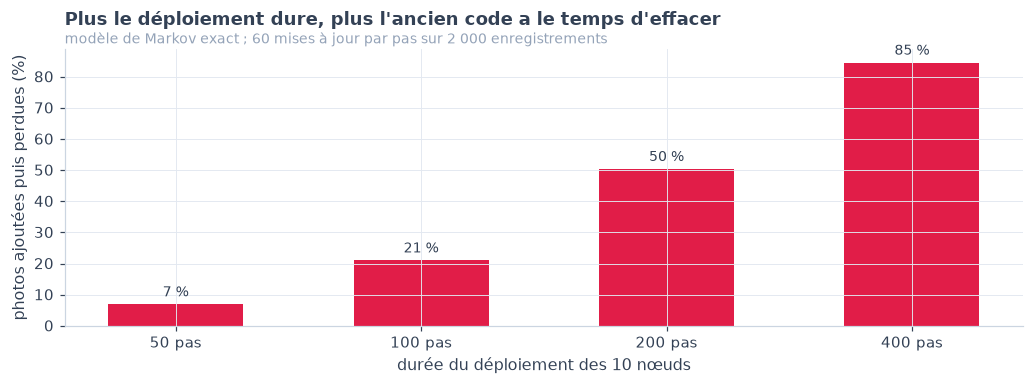

In [3]:
tous = [5, 10, 20, 40]
res = [markov_pertes(tous=k, duree=40 + 10 * k + 200) for k in tous]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.bar([f"{10 * k} pas" for k in tous], [100 * p / (p + c) for c, p in res], color=ROSE, width=0.55)
annotate_bars(ax, "{:.0f} %")
ax.set_xlabel("durée du déploiement des 10 nœuds"); ax.set_ylabel("photos ajoutées puis perdues (%)")
ax.set_title("Plus le déploiement dure, plus l'ancien code a le temps d'effacer")
subtitle(ax, "modèle de Markov exact ; 60 mises à jour par pas sur 2 000 enregistrements")
plt.tight_layout(); plt.show()

Le modèle exact (environ 21 % des photos ajoutées sont perdues, 77 % des enregistrements
ont une photo à la fin) coïncide avec la moyenne des simulations. Allonger le déploiement aggrave fortement
la perte : un déploiement progressif prudent, étalé sur des jours, est justement celui
qui laisse le plus de temps à l'ancien code pour effacer les champs nouveaux. La seule
vraie protection est la préservation des champs inconnus (ou une version intermédiaire
qui les préserve, déployée **avant** celle qui les écrit).

> **À retenir.** La perte de champs inconnus croît avec $\lambda D$ (mises à jour pendant
> la période mixte). Déployer d'abord une version qui sait préserver, puis seulement celle
> qui écrit le nouveau champ, annule le risque.